# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

**Question.** A Jinja fish-export cooperative asks (a) is our harvesting rate sustainable and (b) how risky is our revenue?
The old approach used Fibonacci numbers for the stock and flagged risk when revenue variance exceeded 50,000. We replace both
with defensible tools: logistic growth with harvesting, a bounded random-walk price, the coefficient of variation (CV), and Monte-Carlo
Value-at-Risk. Logic lives in `src/fish.py`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))          # so that `from src.xxx import ...` works

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                              # fixed seed -> Restart & Run All is reproducible
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

import statistics
from src.fish import (fibonacci_stock, FishStock, PriceModel, RiskAssessor, weekly_revenue, describe_revenue,
                      closed_season_mask, closed_season_effect)
BN = 1e9          # UGX billions, for readable tables

## Task 1 - The Fibonacci baseline and why it fails

[1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]
ratios: [2.0, 1.5, 1.667, 1.6, 1.625, 1.615, 1.619, 1.618, 1.618, 1.618, 1.618, 1.618, 1.618]


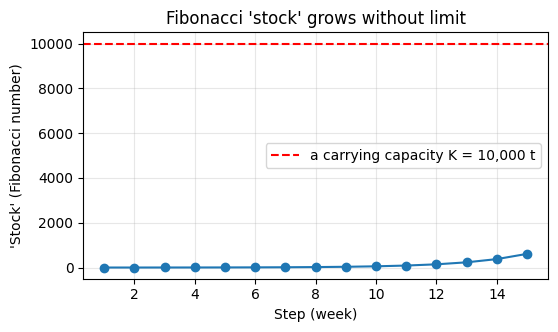

In [2]:
fib = fibonacci_stock(15)
print(fib)
print("ratios:", [round(fib[i+1]/fib[i], 3) for i in range(1, 14)])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(range(1, 16), fib, "o-"); ax.axhline(10_000, color="r", ls="--", label="a carrying capacity K = 10,000 t")
ax.set_xlabel("Step (week)"); ax.set_ylabel("'Stock' (Fibonacci number)"); ax.set_title("Fibonacci 'stock' grows without limit"); ax.legend(); plt.show()

Fibonacci numbers grow by a factor of about 1.618 every step, forever, so the "stock" would double every 1.4 steps and pass any
finite lake capacity within weeks. Real fish stocks are limited by food, space, oxygen and predators, so their growth slows as the population nears the
carrying capacity K. Fibonacci also has no harvest term, no randomness and no notion of a sustainable level, so it cannot answer the
sustainability question. It describes an idealised breeding rabbit population with unlimited resources, not fish in Lake Victoria.

## Task 2 - `FishStock`: discrete logistic growth with harvesting

N(t+1) = N(t) + r N(t) (1 - N(t)/K) - h N(t), with r = 0.4, K = 10,000 t, N(0) = 4,000 t, 52 weekly steps.

In [3]:
fs = FishStock(r=0.4, K=10_000, n0=4_000, h=0.10)
sim = fs.simulate(52)
print(fs)
print("hand check of week 1 (4000 + 0.4*4000*0.6 - 0.1*4000 = 4560):", sim["stock"][1])
print("Equilibrium stock K(1-h/r) =", fs.equilibrium(), "| final stock =", round(sim["stock"][-1], 1))
print("Total catch over 52 weeks: %.0f tonnes" % sim["harvest"].sum())

FishStock(r=0.4, K=10000.0, n0=4000.0, h=0.1)
hand check of week 1 (4000 + 0.4*4000*0.6 - 0.1*4000 = 4560): 4560.0
Equilibrium stock K(1-h/r) = 7500.0 | final stock = 7500.0
Total catch over 52 weeks: 37363 tonnes


## Task 3 - `PriceModel` and weekly revenue

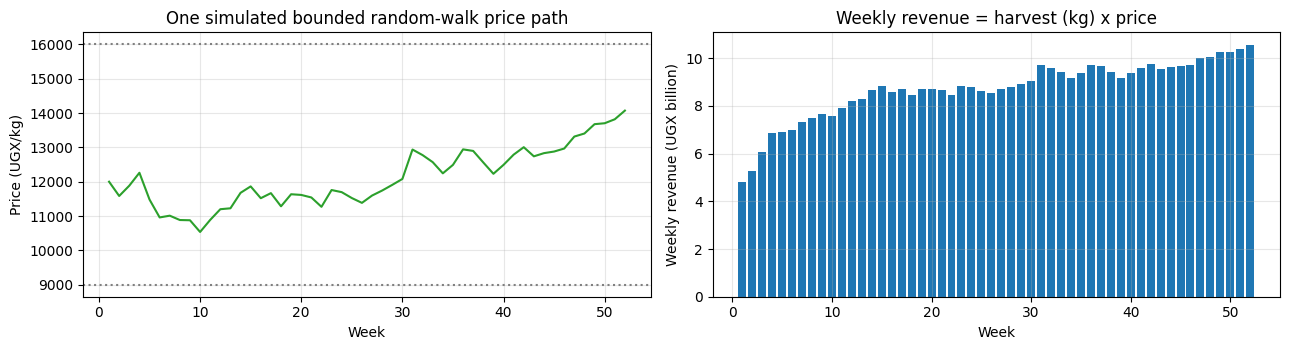

In [4]:
pm = PriceModel(start=12_000, sigma=400, lower=9_000, upper=16_000, seed=SEED)
prices = pm.simulate(52)
revenue = weekly_revenue(sim["harvest"], prices)                # UGX = tonnes x 1000 kg x UGX/kg
weeks = np.arange(1, 53)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(weeks, prices, color="tab:green"); axes[0].axhline(9000, ls=":", c="grey"); axes[0].axhline(16000, ls=":", c="grey")
axes[0].set_xlabel("Week"); axes[0].set_ylabel("Price (UGX/kg)"); axes[0].set_title("One simulated bounded random-walk price path")
axes[1].bar(weeks, revenue / BN, color="tab:blue"); axes[1].set_xlabel("Week"); axes[1].set_ylabel("Weekly revenue (UGX billion)")
axes[1].set_title("Weekly revenue = harvest (kg) x price"); plt.tight_layout(); plt.show()

## Task 4 - Revenue statistics and why a variance threshold of 50,000 is meaningless

In [5]:
d = describe_revenue(revenue)
print(pd.Series(d, name="weekly revenue").to_frame().T.to_string(float_format=lambda v: f"{v:,.4g}"))
print("\nunits -> mean, median, stdev: UGX | variance: UGX^2 | CV: unit-free")

# Change of units changes variance enormously but not CV
for label, scale in [("UGX", 1), ("UGX million", 1e-6), ("UGX billion", 1e-9)]:
    r = list(revenue * scale); s = describe_revenue(r)
    print(f"{label:12s} variance = {s['variance']:>14,.6g}   CV = {s['cv']:.4f}   exceeds 50,000? {s['variance'] > 50_000}")

                    mean   median  variance     stdev     cv
weekly revenue 8.718e+09 8.81e+09 1.505e+18 1.227e+09 0.1407

units -> mean, median, stdev: UGX | variance: UGX^2 | CV: unit-free
UGX          variance =    1.50478e+18   CV = 0.1407   exceeds 50,000? True
UGX million  variance =    1.50478e+06   CV = 0.1407   exceeds 50,000? True
UGX billion  variance =        1.50478   CV = 0.1407   exceeds 50,000? False


**Why 50,000 is meaningless.** Variance has units of *squared* currency (UGX^2). Weekly revenue here is in the billions of shillings, so the variance is
about 10^18 and would exceed 50,000 in *every* scenario, even with a rock-steady price. Measured in billions instead of shillings, the same
data give a variance of about 1.5, below the threshold. The verdict flips when the unit changes while the underlying risk does not, which is a sign that the test is
meaningless. A threshold on variance also ignores the size of the business: a 1,000 UGX wobble is trivial on a UGX 10 billion revenue and huge on a UGX 5,000
one. The **coefficient of variation** CV = st.dev / mean is unit-free and measures risk *relative to typical revenue*, so it is comparable across
harvest rates, currencies and cooperatives.

## Task 5 - `RiskAssessor`: CV rule and Monte-Carlo Value-at-Risk

**Rule (justified).** CV < 0.10 -> *Low*, 0.10-0.25 -> *Moderate*, >= 0.25 -> *High*. These are rule-of-thumb bands from finance and
agricultural-risk practice (income that swings by more than a quarter of its mean is hard to plan loans and payrolls around), and they are parameters
of the class, so a lender can tighten them. We apply the rule to the CV of **annual revenue across 2,000 simulated price paths**, which isolates *price* risk.
**VaR(5 %)** = expected annual revenue minus its 5th percentile: the shortfall that is exceeded in only 1 year out of 20.

In [6]:
ra = RiskAssessor(low=0.10, high=0.25)
mc = ra.monte_carlo(FishStock(h=0.20), pm, n_paths=2000, seed=SEED)
print(f"h = 0.20 | mean annual revenue  : UGX {mc['mean']/BN:8.1f} bn")
print(f"          5th percentile        : UGX {mc['p5']/BN:8.1f} bn")
print(f"          VaR(5%) = mean - p5   : UGX {mc['var_5']/BN:8.1f} bn  ({mc['var_5']/mc['mean']:.1%} of the mean)")
print(f"          CV of annual revenue  : {mc['cv']:.3f}  ->  risk class: {mc['risk']}")

h = 0.20 | mean annual revenue  : UGX    610.8 bn
          5th percentile        : UGX    508.2 bn
          VaR(5%) = mean - p5   : UGX    102.6 bn  (16.8% of the mean)
          CV of annual revenue  : 0.115  ->  risk class: Moderate


## Task 6 - Scenario analysis over harvest rates and comparison with MSY

In [7]:
H = [0.05, 0.10, 0.20, 0.30]
scen = pd.DataFrame(ra.scenarios(H, price_model=pm, n_paths=2000, seed=SEED)).set_index("h")
show = pd.DataFrame({
    "final stock (t)": scen["final_stock_t"],
    "total catch 52 wk (t)": scen["total_catch_t"],
    "total revenue (UGX bn)": scen["total_revenue_UGX"] / BN,
    "annual-revenue CV (MC)": scen["annual_revenue_CV_MC"],
    "revenue risk": scen["risk_class"],
    "VaR 5% (UGX bn)": scen["VaR5_UGX"] / BN,
    "long-run yield (t/wk)": scen["equilibrium_yield_t_per_wk"],
    "long-run yield / MSY": scen["equilibrium_yield_t_per_wk"] / scen["MSY_t_per_wk"],
    "stock status": scen["sustainability"],
})
display(show.round(3))
fs0 = FishStock()
print(f"Theoretical MSY = rK/4 = {fs0.msy:,.0f} t/week, reached at h = r/2 = {fs0.h_msy}; collapse if h >= r = 0.4")

,final stock (t),total catch 52 wk (t),total revenue (UGX bn),annual-revenue CV (MC),revenue risk,VaR 5% (UGX bn),long-run yield (t/wk),long-run yield / MSY,stock status
h,,,,,,,,,
0.050,"8,750.000","21,714.612",263.484,0.117,Moderate,44.704,437.500,0.438,Sustainable
0.100,"7,500.000","37,362.508",453.347,0.117,Moderate,76.620,750.000,0.750,Sustainable
0.200,"4,999.988","50,871.711",616.814,0.115,Moderate,102.554,"1,000.000",1.000,Sustainable
0.300,"2,503.717","42,461.018",512.365,0.108,Moderate,80.907,750.000,0.750,Overfished


Theoretical MSY = rK/4 = 1,000 t/week, reached at h = r/2 = 0.2; collapse if h >= r = 0.4


**Reading the table.** The long-run weekly catch is h x K(1 - h/r): 437.5, 750, **1000** and 750 tonnes for h = 0.05, 0.10, 0.20, 0.30. It peaks at
h = 0.20 where it equals MSY = rK/4 = 1000 t/week. Harvesting *more* (h = 0.30) yields *less* in the long run *and* leaves the stock at 2,500 t, only a quarter of K, which is
biologically risky. An **annual-revenue CV of about 0.11 is nearly the same for all four rates**, because price risk depends on the price process, not on how much is caught.
So the CV rule alone would call every scenario "Moderate": it cannot see stock depletion. That is why we add the separate *stock status* column
(overfished if h > r/2 or the final stock is materially below K/2, i.e. the MSY biomass).

## Task 7 - Charts

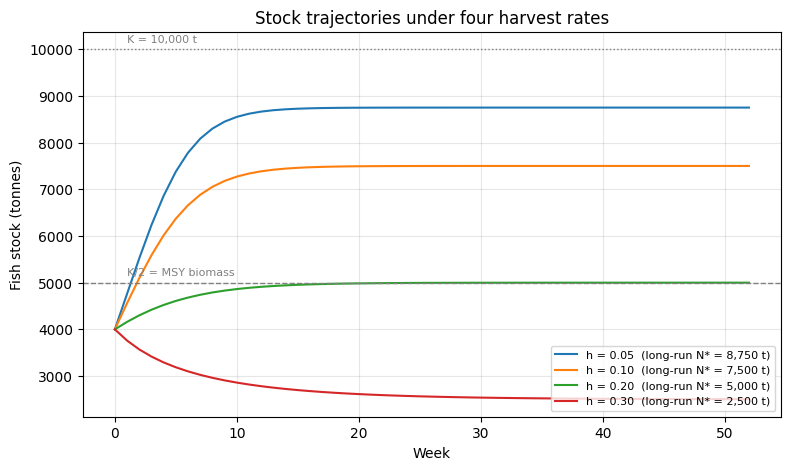

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for h in H:
    f = FishStock(h=h); s = f.simulate(52)["stock"]
    ax.plot(range(53), s, label=f"h = {h:.2f}  (long-run N* = {f.equilibrium():,.0f} t)")
ax.axhline(5000, color="grey", ls="--", lw=1); ax.text(1, 5150, "K/2 = MSY biomass", color="grey", fontsize=8)
ax.axhline(10000, color="grey", ls=":", lw=1); ax.text(1, 10150, "K = 10,000 t", color="grey", fontsize=8)
ax.set_xlabel("Week"); ax.set_ylabel("Fish stock (tonnes)"); ax.set_title("Stock trajectories under four harvest rates")
ax.legend(fontsize=8, loc="lower right"); plt.show()

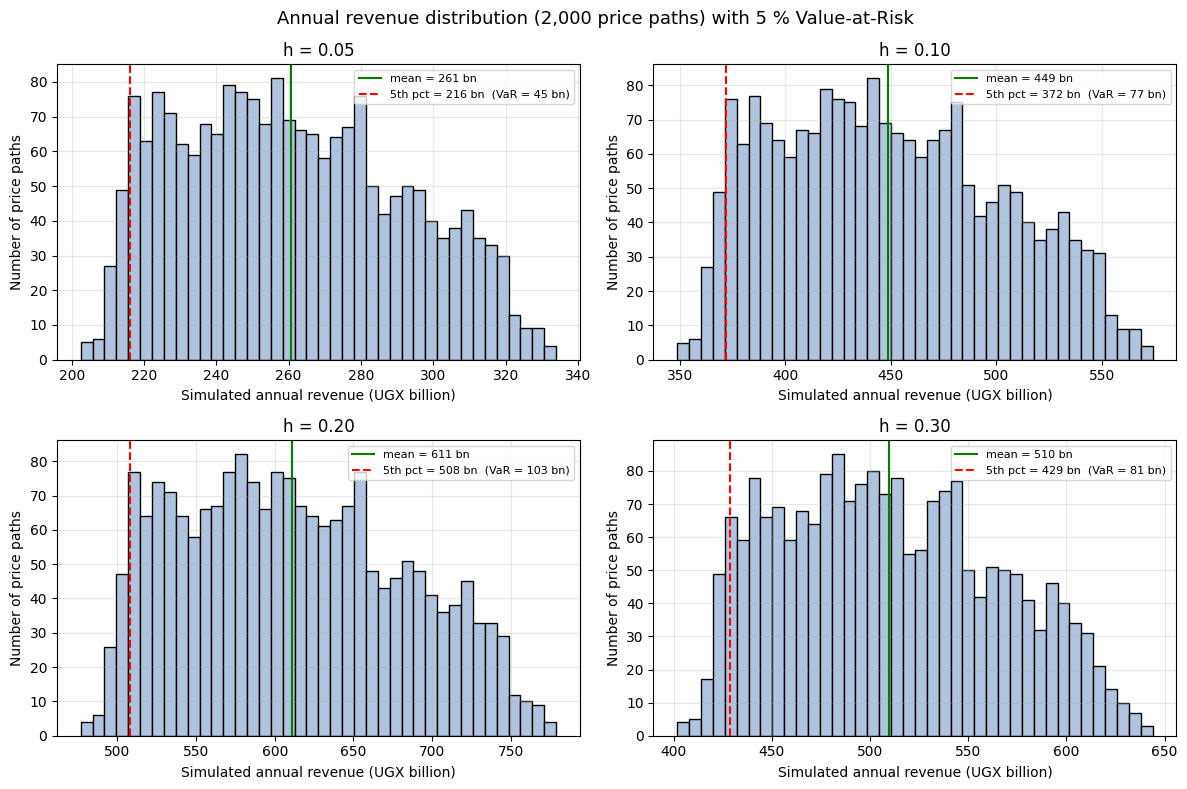

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=False)
for ax, h in zip(axes.ravel(), H):
    m = ra.monte_carlo(FishStock(h=h), pm, n_paths=2000, seed=SEED)
    ax.hist(m["annual"] / BN, bins=40, color="lightsteelblue", edgecolor="k")
    ax.axvline(m["mean"] / BN, color="green", label=f"mean = {m['mean']/BN:.0f} bn")
    ax.axvline(m["p5"] / BN, color="red", ls="--", label=f"5th pct = {m['p5']/BN:.0f} bn  (VaR = {m['var_5']/BN:.0f} bn)")
    ax.set_title(f"h = {h:.2f}"); ax.set_xlabel("Simulated annual revenue (UGX billion)"); ax.set_ylabel("Number of price paths"); ax.legend(fontsize=8)
fig.suptitle("Annual revenue distribution (2,000 price paths) with 5 % Value-at-Risk", fontsize=13)
plt.tight_layout(); plt.show()

## Extension - Closed season (8 weeks per year, weeks 21-28) over 5 years

,"5-yr revenue, open (UGX bn)","5-yr revenue, closed (UGX bn)",change %,"final stock, open (t)","final stock, closed (t)"
h,,,,,
0.050,"1,243.090","1,057.200",-14.950,"8,750.000","8,750.030"
0.100,"2,132.670","1,836.450",-13.890,"7,500.000","7,500.310"
0.200,"2,855.910","2,585.850",-9.460,"5,000.000","5,009.640"
0.300,"2,191.830","2,349.210",7.180,"2,500.000","2,630.860"


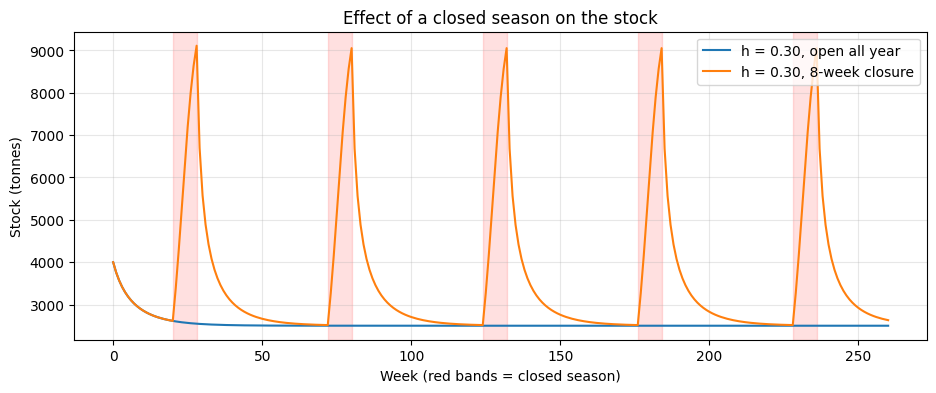

In [10]:
rows = [closed_season_effect(h, years=5, closed_weeks=8, start_week=20, price_model=pm, seed=SEED) for h in H]
cs = pd.DataFrame(rows).set_index("h")
cs_show = pd.DataFrame({"5-yr revenue, open (UGX bn)": cs["revenue_open"] / BN,
                        "5-yr revenue, closed (UGX bn)": cs["revenue_closed"] / BN,
                        "change %": cs["change_pct"], "final stock, open (t)": cs["final_stock_open"],
                        "final stock, closed (t)": cs["final_stock_closed"]})
display(cs_show.round(2))

weeks5 = 52 * 5
mask = closed_season_mask(weeks5, 8, 20)
fig, ax = plt.subplots(figsize=(11, 4))
f = FishStock(h=0.30)
ax.plot(f.simulate(weeks5)["stock"], label="h = 0.30, open all year")
ax.plot(f.simulate(weeks5, mask)["stock"], label="h = 0.30, 8-week closure")
for start in range(20, weeks5, 52): ax.axvspan(start, start + 8, color="red", alpha=0.12)
ax.set_xlabel("Week (red bands = closed season)"); ax.set_ylabel("Stock (tonnes)"); ax.set_title("Effect of a closed season on the stock"); ax.legend(); plt.show()

Same price path in both runs, so differences come only from the closure. A closed season **costs revenue at moderate rates** (h = 0.10 and 0.20: the stock is already
healthy, so eight lost fishing weeks are simply lost catch, as the stock is near its equilibrium and gains almost nothing extra). At the **over-harvest rate h = 0.30** it
**raises** five-year revenue, because the pause lets the depleted stock rebuild and the extra biomass makes later catches larger. The closure is a
sensible tool exactly where the harvest rate is too high, and a poor substitute for choosing the right rate.

## Findings & Limitations

## Findings & Limitations

**Findings.** Fibonacci growth is unbounded, so it cannot describe a lake with a carrying capacity. Under the logistic model with harvesting, the long-run catch peaks at h = 0.20
(1,000 t/week, exactly MSY = rK/4) and falls to 750 t/week at h = 0.10 or 0.30. The h = 0.30 policy is worse than h = 0.20 on every long-run measure: it
catches less and leaves the stock at about 2,500 t, a quarter of K. A 52-week total favours h = 0.20 (about UGX 617 bn against 512 bn for h = 0.30).
Variance thresholds are meaningless because variance carries squared currency units and flips verdict when you change units; CV is
unit-free. Annual-revenue CV is 0.11-0.12 for all four harvest rates, so revenue is "Moderate" risk everywhere, and 5 % VaR is roughly 17 % of expected
revenue. Price risk barely changes with harvest rate; *biological* risk does. An eight-week closed season lowered five-year revenue at h = 0.10 (about -14 %)
and 0.20 (-9 %) but raised it at h = 0.30 (+7 %).

**Limitations.** A weekly growth rate of r = 0.4 is much faster than real Nile perch dynamics. The
model has no age structure, seasonality, environmental shocks, illegal fishing or delayed effects. Harvest is proportional to stock (constant effort), whereas boats
often catch fixed quotas. The random-walk price ignores demand, exchange rates and the correlation between catch and price. Thresholds of 0.10 and 0.25 are conventions, not
estimated from Lake Victoria data. VaR depends on the assumed volatility (sigma = 400 UGX per week), and single-seed comparisons carry sampling noise.